# Site figures

Drawn from `results/`. Presentation only.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "figures" / "site"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, RED, GREY, LIGHT = "#2166ac", "#b2182b", "#8c8c8c", "#d9d9d9"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#eeeeee",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def titled(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")


def save(fig, name):
    fig.savefig(OUT / name, facecolor="white")
    plt.show()


## Calm days against stress days

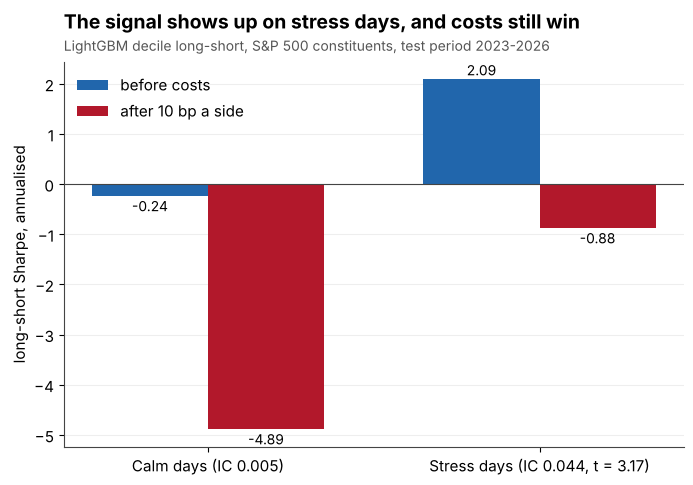

In [2]:
x = pd.read_csv(ROOT / "results/xs_regime_results.csv")
x = x[(x.model == "lightgbm") & (x.regime.isin(["normal", "highvol"]))].set_index("regime").loc[["normal", "highvol"]]
fig, ax = plt.subplots(figsize=(8, 5))
pos = np.arange(2)
w = 0.35
b1 = ax.bar(pos - w / 2, x.ls_sharpe_gross, w, color=BLUE, label="before costs")
b2 = ax.bar(pos + w / 2, x.ls_sharpe_net, w, color=RED, label="after 10 bp a side")
for bars in (b1, b2):
    for b in bars:
        v = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, v + (0.08 if v >= 0 else -0.3), f"{v:.2f}", ha="center", fontsize=10)
ax.axhline(0, color="#444444", lw=0.8)
ax.set_xticks(pos, [f"Calm days (IC {x.ic_mean.iloc[0]:.3f})", f"Stress days (IC {x.ic_mean.iloc[1]:.3f}, t = {x.ic_t.iloc[1]:.2f})"])
ax.set_ylabel("long-short Sharpe, annualised")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left")
titled(ax, "The signal shows up on stress days, and costs still win",
       "LightGBM decile long-short, S&P 500 constituents, test period 2023-2026")
save(fig, "stress_vs_calm.png")

## No model beats predicting zero

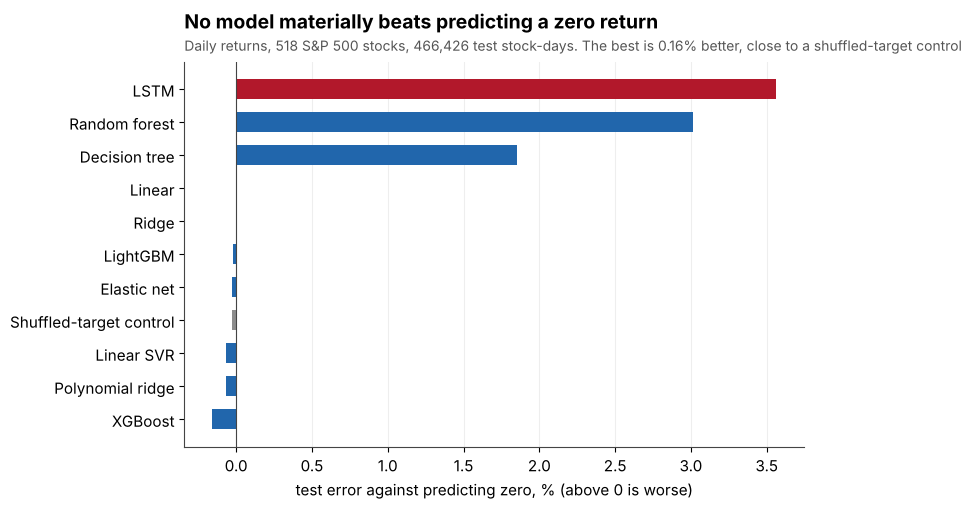

In [3]:
h = pd.read_csv(ROOT / "results/horse_race_results.csv")
h = h[h.split == "test"].set_index("model")
NAMES = {"SANITY_shuffled_ridge": "Shuffled-target control", "linear": "Linear", "ridge": "Ridge", "elasticnet": "Elastic net",
         "decision_tree": "Decision tree", "random_forest": "Random forest", "xgboost": "XGBoost", "lightgbm": "LightGBM",
         "svr_linear": "Linear SVR", "poly2_ridge": "Polynomial ridge", "lstm": "LSTM"}
rel = (h.rmse / h.loc["naive_zero", "rmse"] - 1) * 100
rel = rel.drop([m for m in rel.index if m not in NAMES]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([NAMES[m] for m in rel.index], rel.values, color=[RED if m == "lstm" else GREY if m.startswith("SANITY") else BLUE for m in rel.index], height=0.6)
ax.axvline(0, color="#444444", lw=0.8)
ax.set_xlabel("test error against predicting zero, % (above 0 is worse)")
ax.grid(axis="y", visible=False)
titled(ax, "No model materially beats predicting a zero return",
       "Daily returns, 518 S&P 500 stocks, 466,426 test stock-days. The best is 0.16% better, close to a shuffled-target control")
save(fig, "rmse_vs_zero.png")